<a href="https://colab.research.google.com/github/Swati9369/monthly-expense-profiler/blob/main/Monthly_Expense_Profiler_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- PERSONAL FINANCE PROFILER ---
Enter your total monthly budget in USD (e.g., 2000): 2000
Enter your daily spending limit in USD (e.g., 70): 70

================ YOUR CUSTOM FINANCIAL SUMMARY ================
Monthly Budget Set:     $2,000.00  (₹193,200.00)
Total Spent (USD):       $2,005.89
Total Spent (INR):       ₹193,769.42
Average Daily Spend:     $66.86  (₹6,458.98)
------------------------------------------------------------
Category Totals (USD vs INR):
  • Food           : $  495.68  |  ₹ 47,882.43
  • Transport      : $  491.16  |  ₹ 47,446.06
  • Entertainment  : $  470.07  |  ₹ 45,409.20
  • Utilities      : $  548.98  |  ₹ 53,031.73
------------------------------------------------------------
Days Over Your $70 Limit (12 days): Day(s) [np.int64(1), np.int64(3), np.int64(9), np.int64(13), np.int64(14), np.int64(18), np.int64(19), np.int64(23), np.int64(24), np.int64(27), np.int64(29), np.int64(30)]


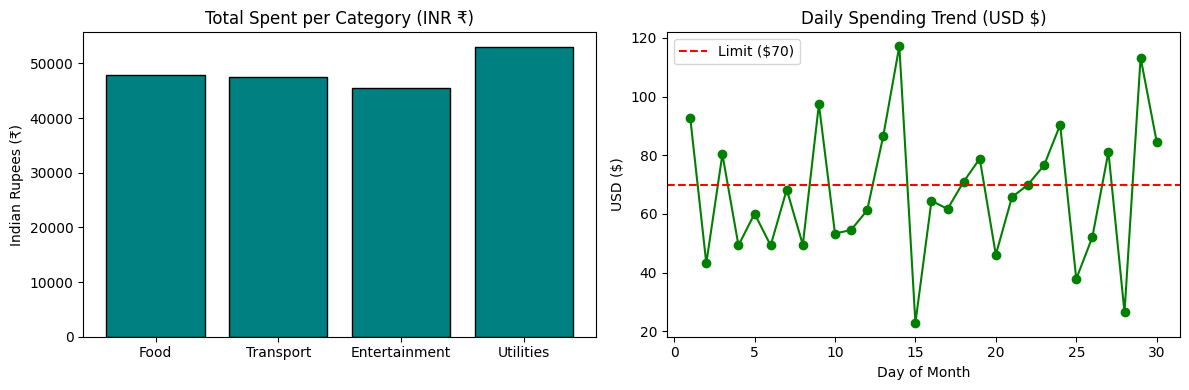

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# STEP 1: USER INPUT (Interactive)
# =====================================================================
print("--- PERSONAL FINANCE PROFILER ---")

# Ask user for custom monthly budget and threshold in USD
monthly_budget = float(input("Enter your total monthly budget in USD (e.g., 2000): "))
daily_threshold = float(input("Enter your daily spending limit in USD (e.g., 70): "))

categories = ["Food", "Transport", "Entertainment", "Utilities"]

# =====================================================================
# STEP 2: DATA GENERATION (Scaled to your input)
# =====================================================================
# Fix random numbers so results are reproducible
np.random.seed(42)

# Generate baseline random weights for 30 days x 4 categories
raw_weights = np.random.rand(30, 4)

# Scale matrix so the overall sum equals your monthly budget
spending_matrix = (raw_weights / np.sum(raw_weights)) * monthly_budget

# Add a missing value to simulate raw data cleaning
spending_matrix[4, 0] = np.nan


# =====================================================================
# STEP 3: DATA CLEANING (Pandas)
# =====================================================================
df = pd.DataFrame(spending_matrix, columns=categories)

# Fill missing value with column mean
df = df.fillna(df.mean())

# Convert back to clean NumPy matrix
clean_matrix = df.to_numpy()


# =====================================================================
# STEP 4: NUMPY ANALYTICS PIPELINE
# =====================================================================
# 1. Sum down columns for category totals (axis=0)
category_totals_usd = np.sum(clean_matrix, axis=0)

# 2. Sum across rows for daily totals (axis=1)
daily_totals_usd = np.sum(clean_matrix, axis=1)

# 3. Overall stats in USD
total_spent_usd = np.sum(clean_matrix)
avg_daily_spend_usd = np.mean(daily_totals_usd)

# 4. Currency Conversion via Vectorized Broadcasting (USD to INR @ 1 USD = ₹83.50)
usd_to_inr_rate = 96.60
matrix_inr = clean_matrix * usd_to_inr_rate

total_spent_inr = np.sum(matrix_inr)
category_totals_inr = np.sum(matrix_inr, axis=0)
avg_daily_spend_inr = avg_daily_spend_usd * usd_to_inr_rate

# 5. Over-Budget Detector (Boolean Masking for days exceeding your USD limit)
over_budget_mask = daily_totals_usd > daily_threshold
over_budget_days = np.where(over_budget_mask)[0] + 1  # Add 1 for day numbers


# =====================================================================
# STEP 5: OUTPUT REPORT & CHARTS
# =====================================================================
print("\n================ YOUR CUSTOM FINANCIAL SUMMARY ================")
print(f"Monthly Budget Set:     ${monthly_budget:,.2f}  (₹{monthly_budget * usd_to_inr_rate:,.2f})")
print(f"Total Spent (USD):       ${total_spent_usd:,.2f}")
print(f"Total Spent (INR):       ₹{total_spent_inr:,.2f}")
print(f"Average Daily Spend:     ${avg_daily_spend_usd:,.2f}  (₹{avg_daily_spend_inr:,.2f})")
print("-" * 60)
print("Category Totals (USD vs INR):")
for cat, usd, inr in zip(categories, category_totals_usd, category_totals_inr):
    print(f"  • {cat:<15}: ${usd:>8,.2f}  |  ₹{inr:>10,.2f}")
print("-" * 60)
print(f"Days Over Your ${daily_threshold:.0f} Limit ({len(over_budget_days)} days): Day(s) {list(over_budget_days)}")
print("===============================================================")

# Visualizations
plt.figure(figsize=(12, 4))

# Plot 1: Category Totals in INR
plt.subplot(1, 2, 1)
plt.bar(categories, category_totals_inr, color='teal', edgecolor='black')
plt.title("Total Spent per Category (INR ₹)")
plt.ylabel("Indian Rupees (₹)")

# Plot 2: Daily Spending Trend (USD) vs Limit
plt.subplot(1, 2, 2)
plt.plot(range(1, 31), daily_totals_usd, marker='o', color='green')
plt.axhline(y=daily_threshold, color='red', linestyle='--', label=f'Limit (${daily_threshold:.0f})')
plt.title("Daily Spending Trend (USD $)")
plt.xlabel("Day of Month")
plt.ylabel("USD ($)")
plt.legend()

plt.tight_layout()
plt.show()